*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

<font color = "darkred">

The ATE is the average outcome of the treatment A group (A) subtracted from the average outcome of the treatment B group (B). Basically, the ATE is the difference in treatment outcomes between the two groups.

In this specific data set, The point estimate of the average treatment effect is the difference between the mean survival rate between the invasive condition and the conservative condition.  If the ate is positive, then the mean survival rate in the invasive treatment condition is higher than the survival rate in the conservative treatment condition. If the ate is negative, then the mean survival rate in the conservative condition is higher than the mean survival rate in the invasive condition. If the ate is zero, there is no mean difference between the groups.

Based on the cross tabulation, in these specific circumstances related to the measures in this experiment, I am unlikely to opt for the intra-aortic balloon pump.

In [2]:
df = pd.read_csv('iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

df.head()

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


,Survived,Group
0,1.0,Invasive
1,1.0,Invasive
2,1.0,Invasive
3,1.0,Invasive
4,1.0,Invasive


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

<font color = "darkred">

KDE: Both groups have a large amount of overlap in high density areas.  The conservative treatment distribution peaks at a higher survival rate than in the invasive condition and is shifted right in comparison to the invasive conditions. Both suggest that the survival rates of the conservative group are more densely populated at higher survival rates, and the most frequent survival rates (peak) are for higher survival rates than for the invasive groups. 

The ECDF also shows that most of the cumulative proportions of survival rates in the conservative group are slightly lower and to the right, indicating a larger proportion in the higher survival rates than in the invasive group.  Despite the differences, the large degree of overlap in shared cumulative proportional values between the two conditions suggests that these slight differences may not be statistically meaningful especially considering that the shift is only 1 percentage point.  

From both the KDE and the ECDF plots, we can see that the distributions are similar both in shape and variability.

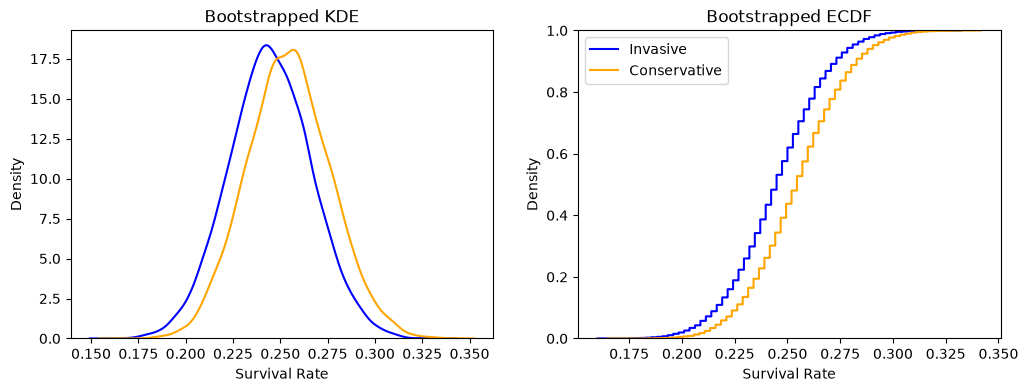

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. 

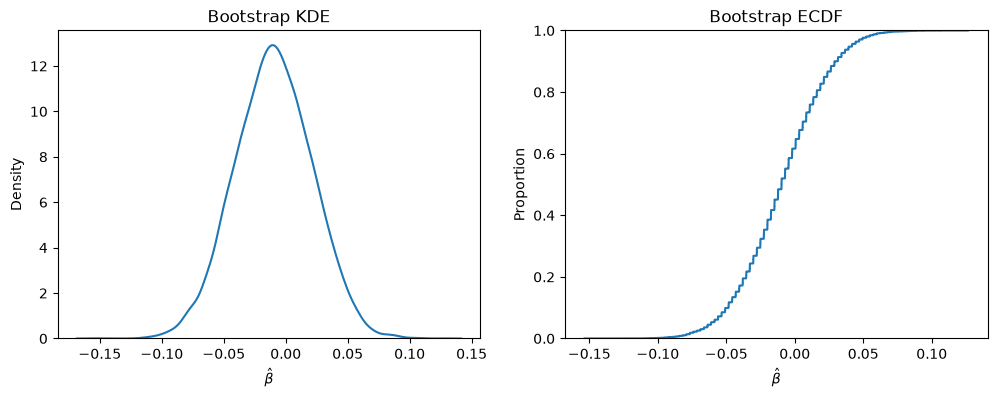

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

<font color = "darkred">

The zero is in all 3 of those intervals, so we fail to reject the null using all criterion (90%, 95% and 99%).

By using bootstrapping, we can be 90, 95, 99% confident that the true mean difference between the two groups lies in the confidence intervals' ranges, respectively.  For all three intervals, zero is within the CI range.  If our criterion to reject the null is the range of the CI not including zero, for all three CIs, we fail to reject the null.  We have no evidence supporting the assertion that the conservative and invasive treatments differ in their outcomes.

Also, we find it important to note that this test does not provide evidence that there is no difference between the two groups.  We are confident that the true CI lies within the CI range, but we have no evidence to favor zero over any of the other values in that range. The overlap with zero, does not provide evidence for zero.

We could potentially assert that if there is a difference, we can be 99% confident that the difference is between from -.09 and .07 and likely to be within this range, but really that is all. 

 If zero were outside of the CI range, we could be confident that the true group difference was unlikely to be zero, so we would have evidence against the null. However, we cannot have evidence for the null using this type of hypothesis testing. If we wanted to test for evidence for the null, we would have to employ bayesian statistics.

 

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06111361  0.04180028]
95% CI: [-0.07136343  0.04957862]
99% CI: [-0.08942441  0.0701177 ]


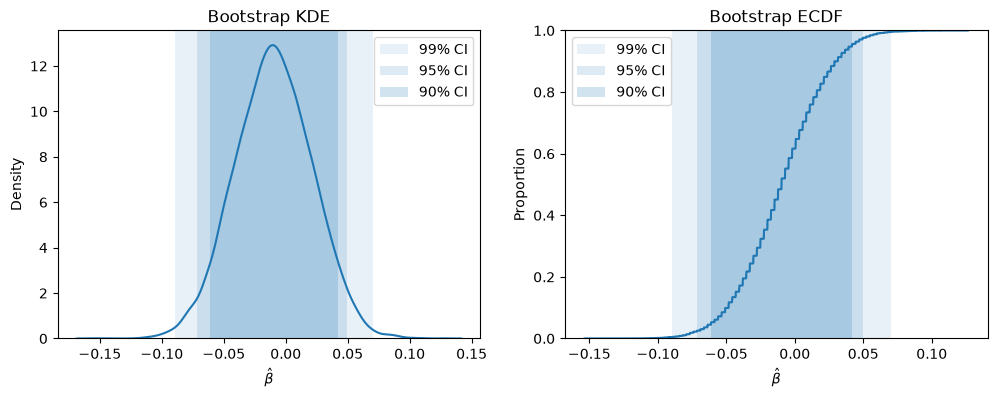

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

<font color = "darkred">
From these data, we have no evidence that inserting balloons into hearts improves survival rates in individuals with chronic kidney disease in comparison to the more conservative treatment.  Our bootstrapped CIs are capable of capturing the true difference between the groups 95% of the time, so we can be relatively certain that the true mean difference is in our CI range. Hence, we can we confident that the true difference is either zero or within -7 to 9 percentage points due to the range of our CI.



Practically, it appears that balloons do not improve lead to meaningfully higher survival rates than conservative treatments to a degree that justifies their cost and risk.  However, we only measured survival rates; it is possible that this treatment improves other measures of import such as quality of life or mobility even if it does not extend survival rates.


Also, we did not have a control group.  We cannot say that inserting balloons had no positive effect as we compared their performance to another established treatment.  For all intents and purposes, the balloons led to similar survival rates as another established treatment. We cannot say they are the same, but we can say that they did not lead to drastically different survival outcomes and the difference in survival rates between the groups is either zero or very small.  Consequently, for individuals who may not be able to receive the conservative treatment of whatever reason, the balloon treatment remains an option.  This paragraph is presuming that both treatments perform better than no treatment at all (which I think can be assumed for the established conservative treatment and from this data, the balloon treatment can be considered similar in terms of mean percentage points). 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [8]:
df_diabetes = pd.read_csv('diabetes.csv')


print(df_diabetes.head())

## Crosstabs, average treatment effect:
print(pd.crosstab( df_diabetes['treatment'], df_diabetes['outcome']), '\n')

df_diabetes['out_n'] = df_diabetes['outcome'].map({'success': 1, 'failure': 0})
print(df_diabetes.groupby('treatment')['out_n'].mean(), '\n')

df_diabetes.head(20)


   Unnamed: 0  treatment  outcome
0           1        met  success
1           2       rosi  failure
2           3       rosi  success
3           4  lifestyle  success
4           5        met  success
outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: out_n, dtype: float64 



,Unnamed: 0,treatment,outcome,out_n
0,1,met,success,1
1,2,rosi,failure,0
2,3,rosi,success,1
3,4,lifestyle,success,1
4,5,met,success,1
5,6,lifestyle,success,1
6,7,lifestyle,success,1
7,8,rosi,success,1
8,9,rosi,success,1
9,10,met,failure,0


In [9]:
ate_lm = df_diabetes.loc[ df_diabetes['treatment'] == 'lifestyle', 'out_n'].mean() \
- df_diabetes.loc[ df_diabetes['treatment'] == 'met', 'out_n'].mean() 
ate_lr = df_diabetes.loc[ df_diabetes['treatment'] == 'lifestyle', 'out_n'].mean() \
- df_diabetes.loc[ df_diabetes['treatment'] == 'rosi', 'out_n'].mean() 
ate_mr = df_diabetes.loc[ df_diabetes['treatment'] == 'met', 'out_n'].mean() \
- df_diabetes.loc[ df_diabetes['treatment'] == 'rosi', 'out_n'].mean() 
print('Estimated ATE: ', np.round(ate_lm, 3), np.round(ate_lr, 3), np.round(ate_mr, 3))

Estimated ATE:  0.051 -0.08 -0.131


In [10]:
## Bootstrapping:
R = 10_000

df_l = df_diabetes.loc[ df_diabetes['treatment'] == 'lifestyle',:]
df_m = df_diabetes.loc[ df_diabetes['treatment'] == 'met',:]
df_r = df_diabetes.loc[ df_diabetes['treatment'] == 'rosi',:]

outcome_l = []
outcome_m = []
outcome_r = []
ate_lm_array = [] # Store computed effects
ate_lr_array = [] # Store computed effects
ate_mr_array = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_lt = df_l.sample(frac=1.0, replace=True)
    df_mt = df_m.sample(frac=1.0, replace=True)
    df_rt = df_r.sample(frac=1.0, replace=True)
    

    olt = df_lt['out_n'].mean() # Mean outcome for l
    omt = df_mt['out_n'].mean() # Mean outcome for m
    ort = df_rt['out_n'].mean() # Mean outcome for r

    ate_lm = olt - omt # Compute ATE for this bootstrap sample
    ate_lr = olt - ort # Compute ATE for this bootstrap sample
    ate_mr = omt - ort # Compute ATE for this bootstrap sample

    outcome_l.append(olt) # Save new value
    outcome_m.append(omt) # Save new value
    outcome_r.append(ort) # Save new value
    ate_lm_array.append(ate_lm) # Save new value
    ate_lr_array.append(ate_lr) # Save new value
    ate_mr_array.append(ate_mr) # Save new value

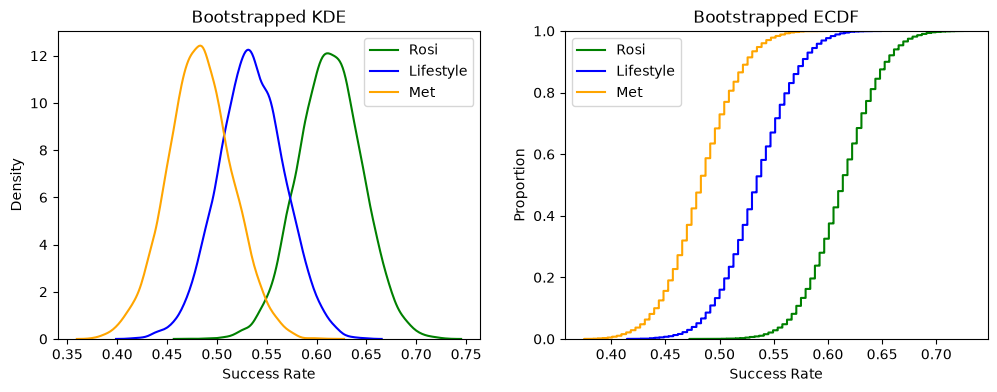

In [11]:
#KDE and ECDF

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(outcome_r, label='Rosi', color='green', ax=ax[0])
sns.kdeplot(outcome_l, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_m, label='Met', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')


sns.ecdfplot(outcome_r, label='Rosi', color='green', ax=ax[1])
sns.ecdfplot(outcome_l, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_m, label='Met', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

ax[0].legend()
ax[1].legend()

plt.show()

<font color = "darkred">

#### Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

Both of the plots show similar shapes and sizes across the three distributions.  The ECDF plot shows roughly similar slopes across all three distributions.  The KDE shows densities in similar symmetrical spreads and peak height.  These similarities between the distributions provide confidence that our distributions are similar enough to make comparisons based on their overlap.


The KDEs and ECDFs show shifts in the positions of curves of the different treatment distributions along the x-axis, i.e. success rate.  Rosi is shifted furthest to the right at the highest success rates, followed by lifestyle in the middle and, finally, met to the farthest left at the lowest success rates.  The largest difference in shift is between rosi and met with lifestyle sandwiched between them. The shift between lifestyle and met is slightly smaller than the shift between lifestyle and rosi.  

<font color = "darkred">

#### Do you find any statistically significant differences between the interventions? Which seems the most effective?

##### Just to clarify here, our numbers may differ from those in the marking rubric, because we performed bonferroni adjustments.

Yes, the difference in success rates for the metformin and rosiglitazone treatment groups is statistically significantly different if our criterion is determined by CI of the 95% of the groups' difference scores not including zero (functionally similar to <em>p</em> < .05), ATE = -0.13, 95% CI[-0.24, -0.02]. From this CI, we can be 95% confident that the true difference between met and rosi is at least 2 to 24 percentage points. 


By this same criterion, comparisons between the lifestyle and rosi (ATE = -0.08, 95% CI[-0.19, 0.03]) and lifestyle and met (ATE= 0.05, 95% CI [-0.06, 0.16]) do not meet this criterion. 


Although the rosi group appears to be the most effective in terms of overall success rates (61.4% success rate), based on our significance testing, we cannot be confident that it is any better than the lifestyle condition (53.4% success rate) based on our data and our analysis. We can conclude that based on this sample in the analysis that rosi (61.4% success rate) is more effective than met (48.3% success rate).  That conclusion is the only one that we can make here.




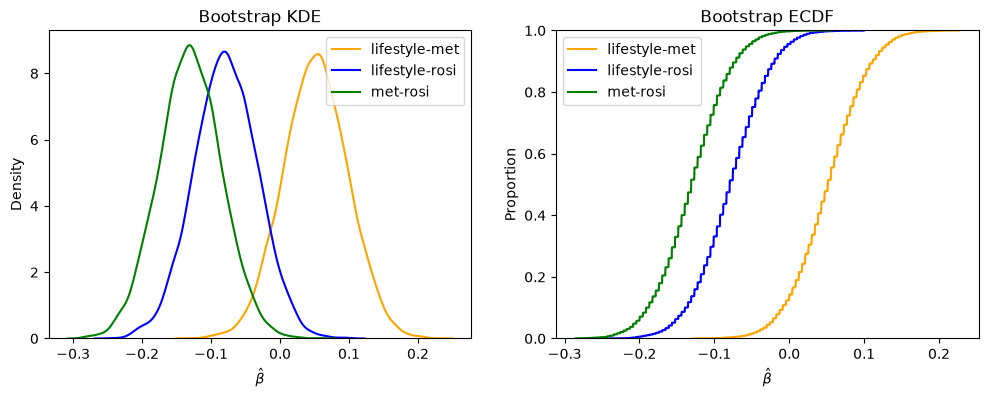

In [12]:
#KDE and ECDF for ATEs

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_lm_array, ax=ax[0], label = "lifestyle-met", color= "orange")
sns.kdeplot(ate_lr_array, ax=ax[0], label = "lifestyle-rosi", color = "blue")
sns.kdeplot(ate_mr_array, ax=ax[0], label = "met-rosi", color = "green")
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate_lm_array, ax=ax[1], label = "lifestyle-met", color = "orange" )
sns.ecdfplot(ate_lr_array, ax=ax[1], label = "lifestyle-rosi", color = "blue")
sns.ecdfplot(ate_mr_array, ax=ax[1], label = "met-rosi", color = "green")
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

ax[0].legend()
ax[1].legend()
plt.show()

In [13]:
# We used the bonferroni corrected CIs
ci95_lm = np.quantile(ate_lm_array, [.025, .975])
ci95_lr = np.quantile(ate_lr_array, [.025, .975])
ci95_mr = np.quantile(ate_mr_array, [.025, .975])

#bonferroni corrected alpha/3, .0167
ci95_lm_bc = np.quantile(ate_lm_array, [.0083, .9917])
ci95_lr_bc = np.quantile(ate_lr_array, [.0083, .9917])
ci95_mr_bc = np.quantile(ate_mr_array, [.0083, .9917])


ci90_lm = np.quantile(ate_lm_array, [.05, .95])
ci90_lr = np.quantile(ate_lr_array, [.05, .95])
ci90_mr = np.quantile(ate_mr_array, [.05, .95])

#bonferroni corrected alpha/3, .10/3 = .033 
ci90_lm_bc = np.quantile(ate_lm_array, [.0167, .9833])
ci90_lr_bc = np.quantile(ate_lr_array, [.0167, .9833])
ci90_mr_bc = np.quantile(ate_mr_array, [.0167, .9833])

ci99_lm = np.quantile(ate_lm_array, [.005, .995])
ci99_lr = np.quantile(ate_lr_array, [.005, .995])
ci99_mr = np.quantile(ate_mr_array, [.005, .995])

#bonferroni corrected alpha/3, .01/3 = .0033
ci99_lm_bc = np.quantile(ate_lm_array, [.0017, .9983])
ci99_lr_bc = np.quantile(ate_lr_array, [.0017, .9983])
ci99_mr_bc = np.quantile(ate_mr_array, [.0017, .9983])


print(f"95% CI (lifestyle - met) Bonferroni corrected: {ci95_lm_bc}")
print(f"95% CI (lifestyle - rosi) Bonferroni corrected: {ci95_lr_bc}")
print(f"95% CI (met - rosi) Bonferroni corrected: {ci95_mr_bc}")

print(f"90% CI (lifestyle - met) Bonferroni corrected: {ci90_lm_bc}")
print(f"90% CI (lifestyle - rosi) Bonferroni corrected: {ci90_lr_bc}")
print(f"90% CI (met - rosi) Bonferroni corrected: {ci90_mr_bc}")

print(f"99% CI (lifestyle - met) Bonferroni corrected: {ci99_lm_bc}")
print(f"99% CI (lifestyle - rosi) Bonferroni corrected: {ci99_lr_bc}")
print(f"99% CI (met - rosi) Bonferroni corrected: {ci99_mr_bc}")

95% CI (lifestyle - met) Bonferroni corrected: [-0.06034483  0.16309313]
95% CI (lifestyle - rosi) Bonferroni corrected: [-0.19509556  0.02762264]
95% CI (met - rosi) Bonferroni corrected: [-0.23858591 -0.01916516]
90% CI (lifestyle - met) Bonferroni corrected: [-0.04745063  0.15008903]
90% CI (lifestyle - rosi) Bonferroni corrected: [-0.17805656  0.01892814]
90% CI (met - rosi) Bonferroni corrected: [-0.22972473 -0.03207785]
99% CI (lifestyle - met) Bonferroni corrected: [-0.09022289  0.18880784]
99% CI (lifestyle - rosi) Bonferroni corrected: [-0.212263   0.0617367]
99% CI (met - rosi) Bonferroni corrected: [-0.26429999  0.00665982]


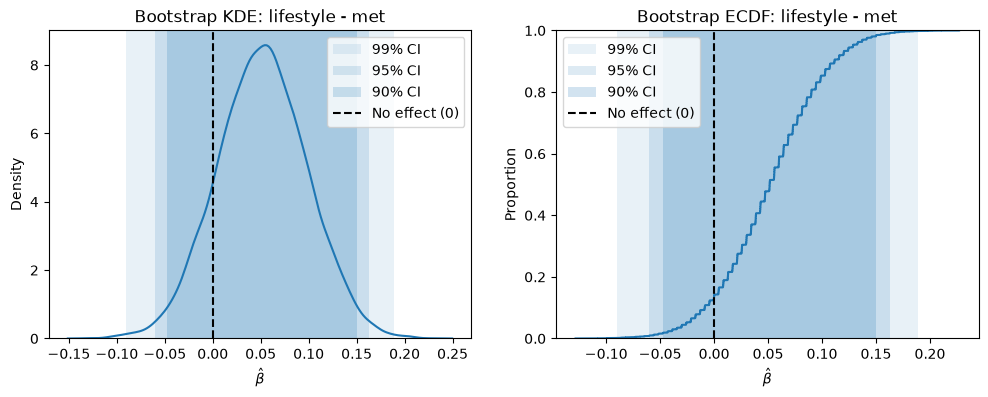

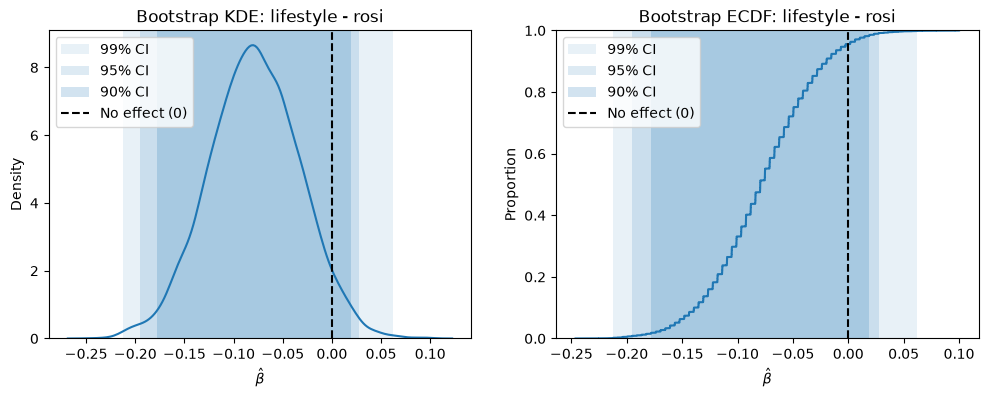

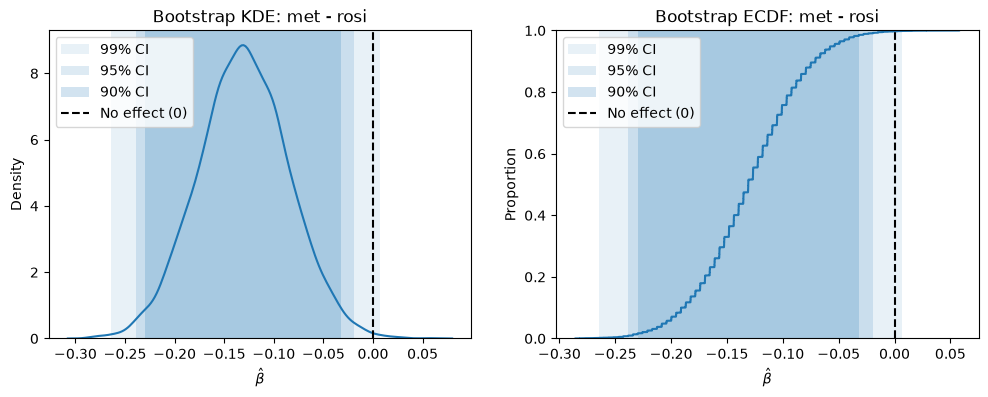

In [14]:


comparisons = [("lifestyle - met", ate_lm_array),
               ("lifestyle - rosi", ate_lr_array),
               ("met - rosi", ate_mr_array)]

for name, arr in comparisons:
    # Percentile bootstrap confidence intervals
    ci90 = np.quantile(arr, [.0167, .9833])
    ci95 = np.quantile(arr, [.0083, .9917])
    ci99 = np.quantile(arr, [.0017, .9983])

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ## KDE
    sns.kdeplot(arr, ax=ax[0])
    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[0].axvline(0, color="black", linestyle="--", label="No effect (0)")
    ax[0].set_xlabel(r"$\hat{\beta}$")
    ax[0].set_title(f"Bootstrap KDE: {name}")
    ax[0].legend()

    ## ECDF
    sns.ecdfplot(arr, ax=ax[1])
    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")
    ax[1].axvline(0, color="black", linestyle="--", label="No effect (0)")
    ax[1].set_xlabel(r"$\hat{\beta}$")
    ax[1].set_title(f"Bootstrap ECDF: {name}")
    ax[1].legend()
    fig.savefig("ate_met_rosi.png", dpi=150, bbox_inches="tight")
    plt.show()

<font color = "darkred">

#### Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In this analysis, we assess the difference in binary success versus failure outcomes between three different groups of patients at risk for diabetes who were randomly assigned to different treatment groups (N= 699).  One group engaged in a treatment involving changes in lifestyle, hereafter referred to as "lifestyle" (n= 234).  Another group was treated using a medication called metformin, hereafter referred to as "met" (n= 232).  Finally, the last group was treated using a medication called rosiglitazone, hereafter referred to as "rosi" (n= 233). Treatment outcome was operationally defined as a binary dependent measure, where a success was recorded (success = 1) if the patient did not develop type II diabetes (no other information on the outcome variable was provided), see Table 1.  

To assess the differences in success between the three groups, we conducted AB comparisons between the three treatment groups.  We created a bootstrap sampling distribution for each treatment group's success rate (10,000 resamples); resampling was performed separately for each group to maintain the randomized group sizes.  For each bootstrap, we calculated the difference in success rates between each pair of treatment groups for those samples (lifestyle versus met, lifestyle versus rosi, and met versus rosi), referred to as the average treatment effect of one group in relation to the other group.  We determined 90/95/99% confidence intervals of the three ATEs by taking the percentiles of the bootstrapped distributions of the ATEs.  We determined that one treatment's outcome would be significantly different from another if the 95%CI of the ATEs for those groups did not contain zero. We used Bonferroni corrections on our CIs to control for multiple comparisons.

| Treatment | n | Successes | Success rate |
|---|---|---|---|
| Lifestyle | 234 | 125 | 53.4% |
| Metformin (met) | 232 | 112 | 48.3% |
| Rosiglitazone (rosi) | 233 | 143 | 61.4% |
| **Total** | **699** | **380** | **54.4%** |

<em>Table 1.</em> Different treatments groups and their success rates



We found that those in the rosi group had a statistically significantly higher success rate (61.4%) than those in the met group (48.3%), ATE = -0.13, 95% CI[-0.239, -0.019], all CIs Bonferroni corrected, see Figure 1.  We did not find any other statistically significant differences between the other comparisons.  Consequently, we have some evidence suggesting that the rosi treatment is superior to the met treatment in success rates; however, we do not have any evidence that it resulted in better success rates than the lifestyle treatment (53.4%), ATE = -0.08, 95% CI[-0.191, 0.028] and we also have no evidence that the lifestyle and met treatments differ in their success rates, ATE = 0.05, 95% CI[-0.060, 0.163].  In the absence of a control group, we also have little evidence that these treatments are better or worse than no treatment at all.

<img src="ate_met_rosi.png" width="700">

*Figure 1.* Bootstrap distribution of the met − rosi ATE, with Bonferroni-corrected CIs.

Overall, we recommend interpreting the findings in this analysis with reservation.  We have a relatively small sample size for a binary outcome, and we did not include any other parameters in our analysis outside of treatment group which could help account for some of the outcome variability making the variability associated with treatment difference more apparent and refined. As such, we also have no idea about how these treatments' outcomes are modulated due to individual differences.  Additionally, we have limited information on how success versus failure was determined and at what point in the treatment, and we might find that alternative measures of success, i.e., blood glucose levels, would be more sensitive to possible differences in each treatment. We can be confident that rosi led to a higher success rate than the met treatment for our overall sample. We cannot make any other conclusions about the relative efficacy of the treatments. In terms of interventions, we could potentially recommend the rosi treatment over the met, but not over the lifestyle.  We also cannot recommend the lifestyle over the met.  For all three treatments, we cannot really recommend them as interventions over no treatment either as we did not compare them to a control group.





